# Chinese world: birth + 35 vs impact years
Two ways to place the same individuals in time. **Birth + 35** counts each person once, at age 35. **Impact years** counts each person in every year from age 30 to 60 (death year if they died before 30, the year before death if they died before 60).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
ZOOM_FIRST, ZOOM_LAST = 1550, 1750
POINT_AGE = 35
IMPACT_START_AGE, IMPACT_END_AGE = 30, 60
PRECISE = ['day', 'month', 'year']

SERIES_COLORS = {'Birth + 35': ORANGE, 'Impact years': BLUE}

apply_style()

## Load data — Chinese-world individuals with a birth year

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
individuals = con.execute('''
    WITH chinese_polities AS (
        SELECT DISTINCT name FROM polity WHERE list_contains(world, 'Chinese world')
    ),
    chinese_individuals AS (
        SELECT DISTINCT entity.qid AS qid
        FROM (SELECT entity, unnest(polity) AS match FROM individual_enriched)
        WHERE match.polity.name IN (SELECT name FROM chinese_polities)
    )
    SELECT chinese_individuals.qid,
           list_filter(individual.birth_date, d -> list_contains($precise, d.precision))[1].year AS birth_year,
           list_filter(individual.death_date, d -> list_contains($precise, d.precision))[1].year AS death_year
    FROM chinese_individuals
    JOIN individual ON individual.entity.qid = chinese_individuals.qid
''', {'precise': PRECISE}).pl()
con.close()

assert individuals['qid'].n_unique() == individuals.height
print(f'{individuals.height:,} Chinese-world individuals')
individuals = individuals.filter(pl.col('birth_year').is_not_null())
print(f'{individuals.height:,} with a birth year (day, month or year precision)')
individuals.sample(5, seed=0)

88,845 Chinese-world individuals
87,671 with a birth year (day, month or year precision)


qid,birth_year,death_year
str,i64,i64
"""Q45430906""",1059,1125
"""Q167480""",81,121
"""Q45381751""",1211,1275
"""Q45534555""",1858,1892
"""Q45436829""",810,863


## Preprocessing
### Impact window per individual

In [3]:
died_before_start = pl.col('death_year') < pl.col('birth_year') + IMPACT_START_AGE
died_before_end = pl.col('death_year') < pl.col('birth_year') + IMPACT_END_AGE

individuals = individuals.with_columns(
    (pl.col('birth_year') + POINT_AGE).alias('point_year'),
    pl.when(died_before_start).then(pl.col('death_year'))
      .otherwise(pl.col('birth_year') + IMPACT_START_AGE).alias('impact_start'),
    pl.when(died_before_start).then(pl.col('death_year'))
      .when(died_before_end).then(pl.col('death_year') - 1)
      .otherwise(pl.col('birth_year') + IMPACT_END_AGE).alias('impact_end'),
)
before = individuals.height
individuals = individuals.filter(pl.col('impact_end') >= pl.col('impact_start'))
print(f'{before - individuals.height:,} dropped: death before birth')
assert (individuals['impact_end'] - individuals['impact_start']).max() == IMPACT_END_AGE - IMPACT_START_AGE
individuals.sample(5, seed=0)

151 dropped: death before birth


qid,birth_year,death_year,point_year,impact_start,impact_end
str,i64,i64,i64,i64,i64
"""Q15906821""",1653,1721,1688,1683,1713
"""Q934891""",1514,1587,1549,1544,1574
"""Q45379304""",1067,1124,1102,1097,1123
"""Q45534662""",1269,1347,1304,1299,1329
"""Q45437841""",796,856,831,826,856


### Yearly counts

In [4]:
years = pl.DataFrame({'year': np.arange(FIRST_YEAR, LAST_YEAR + 1)})

point_counts = individuals.group_by(pl.col('point_year').alias('year')).len('birth_35')
impact_counts = (
    individuals.select(pl.int_ranges('impact_start', pl.col('impact_end') + 1).alias('year'))
    .explode('year')
    .group_by('year').len('impact')
)
yearly = (
    years.join(point_counts, on='year', how='left')
    .join(impact_counts, on='year', how='left')
    .with_columns(pl.col('birth_35', 'impact').fill_null(0))
)
print(f"individuals counted at birth + 35 in {FIRST_YEAR}–{LAST_YEAR}: {yearly['birth_35'].sum():,}")
yearly.filter(pl.col('year').is_between(1640, 1650))

individuals counted at birth + 35 in -500–1900: 85,164


year,birth_35,impact
i64,u32,u32
1640,76,2078
1641,80,2123
1642,78,2166
1643,74,2175
1644,72,2173
…,…,…
1646,101,2155
1647,119,2196
1648,112,2272


### Check: are birth years rounded?
If birth years were rounded estimates, far more than 10% would end in 0 or 5. They do not, so the gap between the two series below comes from how people are counted, not from rounded dates.

In [5]:
in_range = individuals.filter(pl.col('birth_year').is_between(FIRST_YEAR, LAST_YEAR))
last_digit = in_range.with_columns((pl.col('birth_year') % 10).alias('last_digit'))
digit_shares = (
    last_digit.group_by('last_digit').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum()).round(1).alias('pct'))
    .sort('last_digit')
)
digit_shares

last_digit,len,pct
i64,u32,f64
0,9028,10.3
1,8647,9.9
2,8648,9.9
3,8489,9.7
4,8715,10.0
5,8698,9.9
6,9214,10.5
7,8489,9.7
8,8729,10.0


### Largest birth-year clusters
One birth year shared by hundreds of people becomes a one-year spike in the birth + 35 series. In the impact series the same people spread over 31 years.

In [6]:
top_births = (
    in_range.group_by('birth_year', 'death_year').len()
    .sort('len', descending=True)
    .head(5)
)
top_births

birth_year,death_year,len
i64,i64,u32
698,760,340
760,820,231
735,797,198
664,723,193
731,793,190


### Year-to-year noise
Mean absolute change from one year to the next, as a share of the mean level. A curve that jumps around from one year to the next scores high.

In [7]:
def roughness(series):
    return 100 * series.diff().abs().mean() / series.mean()

zoom = yearly.filter(pl.col('year').is_between(ZOOM_FIRST, ZOOM_LAST))
noise = pl.DataFrame({
    'series': list(SERIES_COLORS),
    f'{FIRST_YEAR}–{LAST_YEAR}': [roughness(yearly['birth_35']), roughness(yearly['impact'])],
    f'{ZOOM_FIRST}–{ZOOM_LAST}': [roughness(zoom['birth_35']), roughness(zoom['impact'])],
}).with_columns(pl.exclude('series').round(1))
noise

series,-500–1900,1550–1750
str,f64,f64
"""Birth + 35""",24.5,14.3
"""Impact years""",1.5,1.2


## Figures
Real counts, one panel per series. The impact series counts each person in up to 31 years, so its level is higher.

In [8]:
PANELS = [('birth_35', 'Birth + 35 (each person once)', 1.0),
          ('impact', 'Impact years (each year from age 30 to 60)', 2.2)]


def plot_series(frame, xlim):
    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    for ax, (column, label, width), color in zip(axes, PANELS, SERIES_COLORS.values()):
        ax.plot(frame['year'], frame[column], color=color, linewidth=width)
        ax.text(0.01, 0.95, label, transform=ax.transAxes, va='top', fontsize=16, color=color)
        ax.set_ylim(0, frame[column].max() * 1.2)
        ax.yaxis.set_major_formatter(THOUSANDS)
        ax.grid(axis='y')
    axes[-1].set_xlim(*xlim)
    axes[-1].set_xlabel('Year')
    fig.tight_layout()
    plt.show()

### Figure: birth + 35 vs impact years, Chinese world

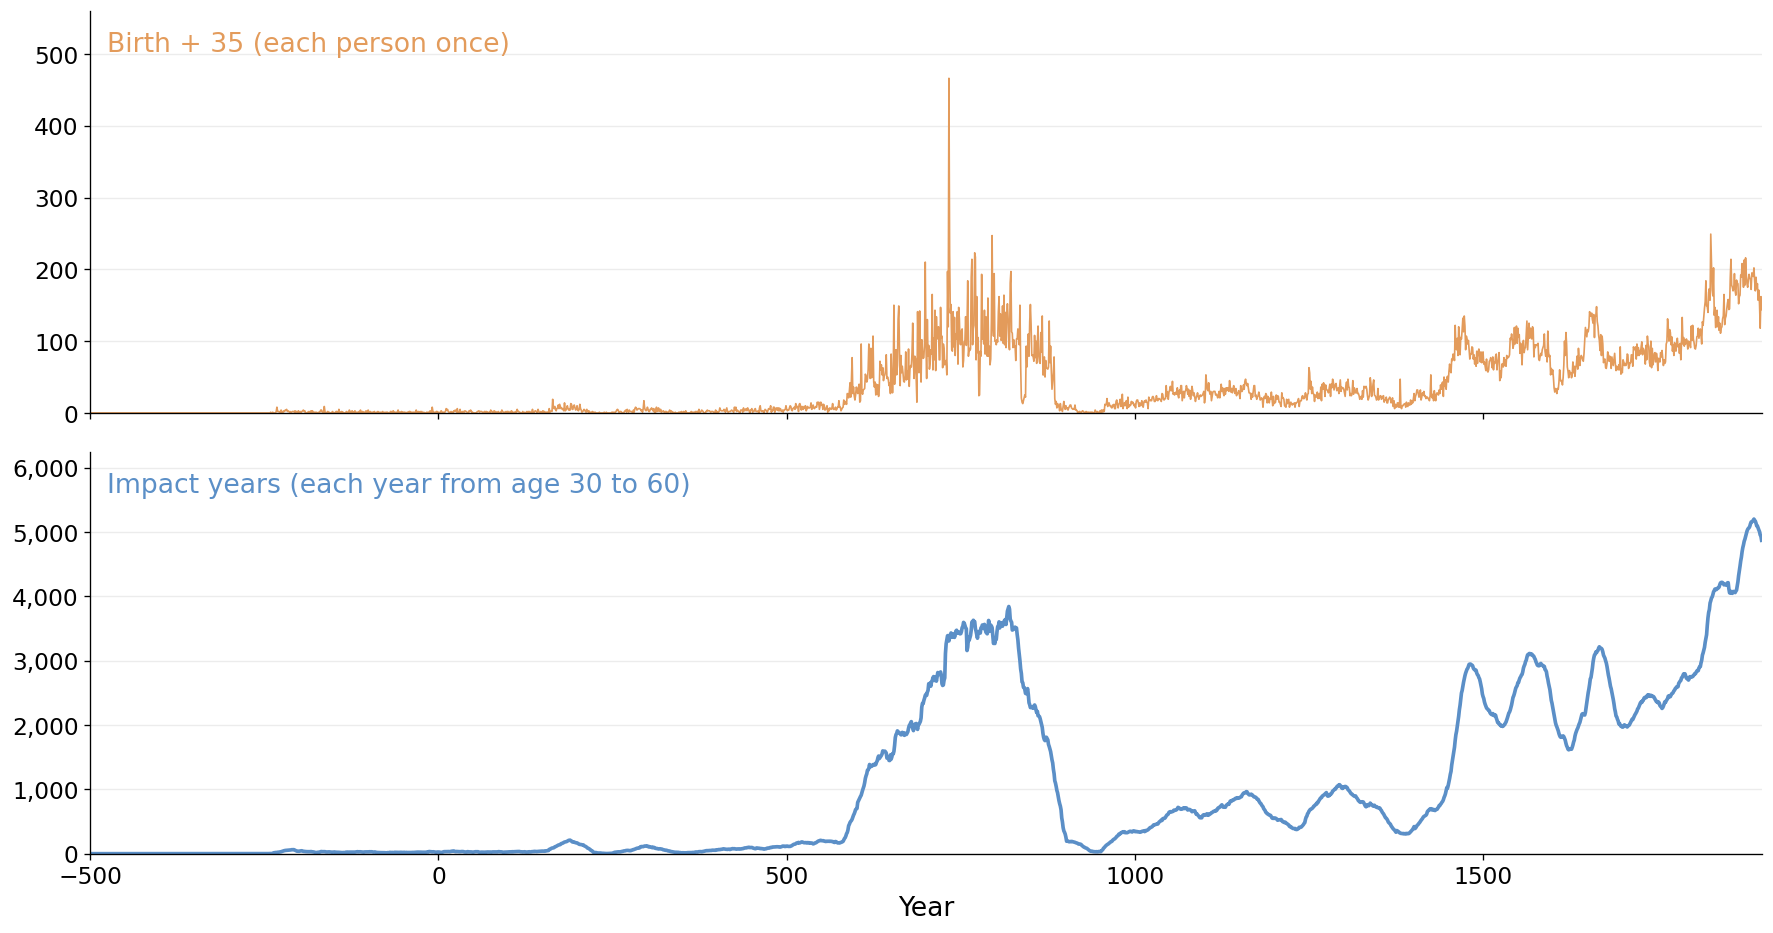

In [9]:
plot_series(yearly, (FIRST_YEAR, LAST_YEAR))

### Figure: zoom on the Ming–Qing transition

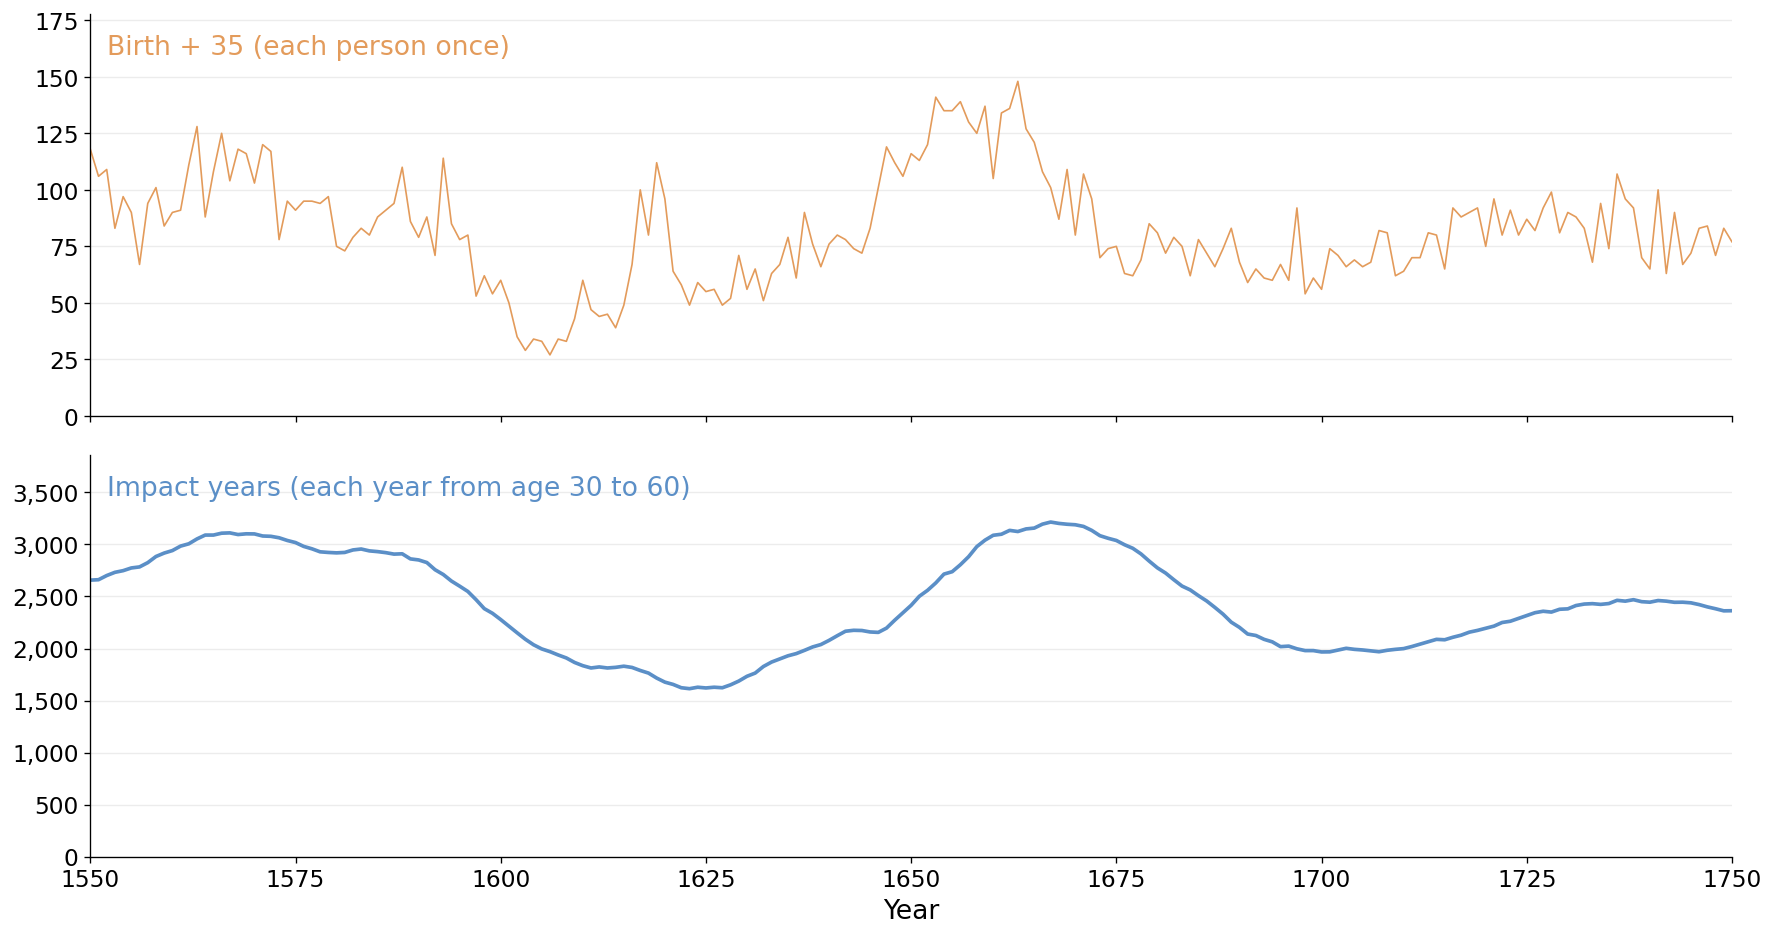

In [10]:
plot_series(zoom, (ZOOM_FIRST, ZOOM_LAST))